In [1]:
#Importing libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
#Importing data

In [4]:
sales = pd.read_csv("../data/sales_daily.csv", parse_dates=["date"])
products = pd.read_csv("../data/products.csv", parse_dates=["launch_date", "end_of_life_date"])
calendar = pd.read_csv("../data/marketing_calendar.csv", parse_dates=["start_date", "end_date"])

print("sales:   ", sales.shape)
print("products:", products.shape)
print("calendar:", calendar.shape)

sales:    (36775, 10)
products: (40, 13)
calendar: (4, 5)


In [5]:
#Data exploration:

In [6]:
#let's look at the table structure

In [7]:
sales.head()

,date,sku,units_sold,list_price_eur,discount_pct,selling_price_eur,campaign_id,stock_end_of_day,stockout_flag,revenue_eur
0,2023-09-04,SKU001,9,299.0,0.0,299.0,NaN,555,0,2691.0
1,2023-09-05,SKU001,7,299.0,0.0,299.0,NaN,548,0,2093.0
2,2023-09-06,SKU001,6,299.0,0.0,299.0,NaN,542,0,1794.0
3,2023-09-07,SKU001,2,299.0,0.0,299.0,NaN,540,0,598.0
4,2023-09-08,SKU001,6,299.0,0.0,299.0,NaN,534,0,1794.0


In [8]:
products.head()

,sku,product_name,category,supplier_id,family,predecessor_sku,launch_date,end_of_life_date,launch_price_eur,moq_units,case_pack_units,unit_cost_eur,q4_2026_allocation_units
0,SKU001,Noise-Cancelling Headphones Gen 1,Audio,SUP02,HEADPHONES,NaN,2023-09-04,2025-04-30,299,60,6,182.40,NaN
1,SKU002,Noise-Cancelling Headphones Gen 2,Audio,SUP02,HEADPHONES,SKU001,2025-04-07,2026-10-31,329,70,10,197.72,NaN
2,SKU003,Noise-Cancelling Headphones Gen 3,Audio,SUP02,HEADPHONES,SKU002,2026-09-21,NaT,349,66,6,203.13,336.0
3,SKU004,Wireless Earbuds Gen 1,Audio,SUP02,EARBUDS,NaN,2023-10-02,2025-10-31,149,140,10,97.27,NaN
4,SKU005,Wireless Earbuds Gen 2,Audio,SUP02,EARBUDS,SKU004,2025-09-22,NaT,169,90,10,121.01,520.0


In [9]:
calendar.head()

,event,year,start_date,end_date,status
0,Black Week,2023,2023-11-20,2023-11-27,completed
1,Black Week,2024,2024-11-25,2024-12-02,completed
2,Black Week,2025,2025-11-24,2025-12-01,completed
3,Black Week,2026,2026-11-23,2026-11-30,planned


In [10]:
#We check how many products for category

In [11]:
products.category.value_counts()

category
Computing & Mobile    13
TV & Smart Home       11
Audio                  7
Gaming                 5
Wearables              4
Name: count, dtype: int64

In [12]:
#We agregate sales per week

In [13]:
weekly = sales.set_index("date").units_sold.resample("W").sum()


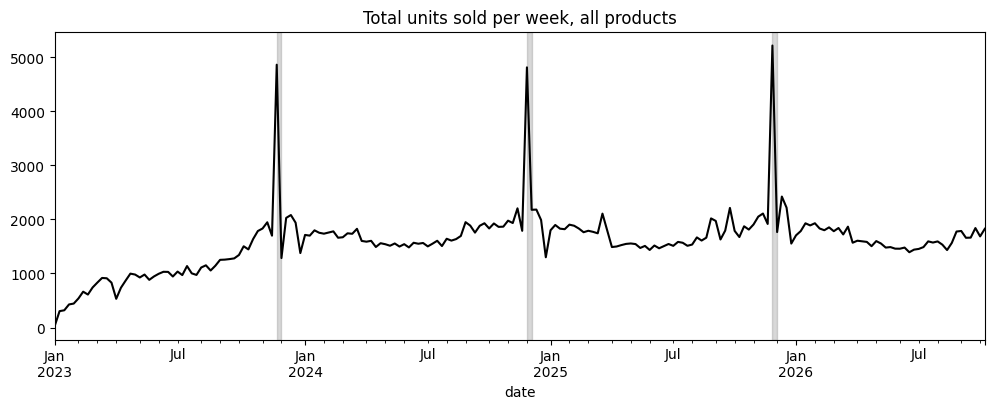

In [14]:
ax = weekly.plot(figsize=(12, 4), color="black", title="Total units sold per week, all products")
for row in calendar[calendar.status == "completed"].itertuples():
    ax.axvspan(row.start_date, row.end_date, color="grey", alpha=0.3)
plt.show()

In [15]:
#First week has very low values because it does not contain 7 days

In [16]:
for row in calendar[calendar.status == "completed"].itertuples():
    units = sales[sales.date.between(row.start_date, row.end_date)].units_sold.sum()
    print(row.year, f"{units:,} units")

2023 5,385 units
2024 5,491 units
2025 5,892 units


In [17]:
#Checking one sku

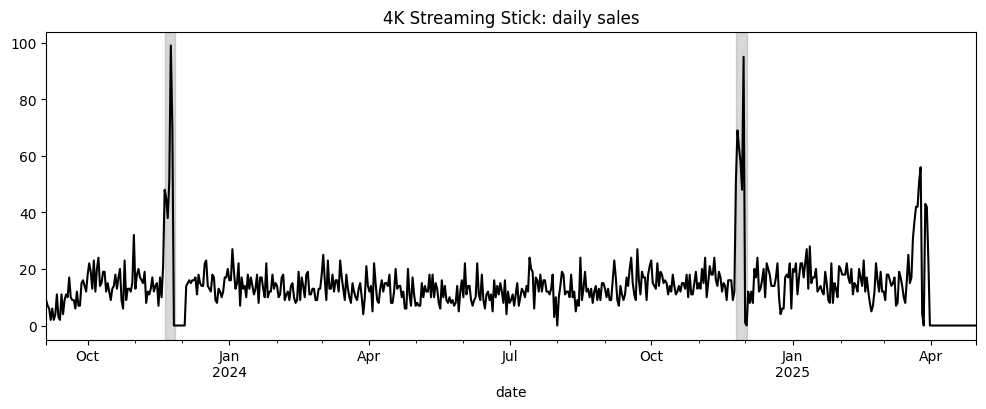

In [18]:
one = sales[sales.sku == "SKU001"].set_index("date")

ax = one.units_sold.plot(figsize=(12, 4), color="black", title="4K Streaming Stick: daily sales")
for row in calendar[calendar.status == "completed"].itertuples():
    ax.axvspan(row.start_date, row.end_date, color="grey", alpha=0.3)
plt.show()

In [19]:
#each calendar row  to be identified by year

In [20]:
calendar = calendar.set_index("year")
print(calendar)


           event start_date   end_date     status
year                                             
2023  Black Week 2023-11-20 2023-11-27  completed
2024  Black Week 2024-11-25 2024-12-02  completed
2025  Black Week 2025-11-24 2025-12-01  completed
2026  Black Week 2026-11-23 2026-11-30    planned


In [23]:
calendar.loc[2024, "start_date"]

Timestamp('2024-11-25 00:00:00')

In [24]:
#important to filter out the SKUs that were in the previous black weeks on sale

In [26]:
in_bw_2023 = sales.date.between(calendar.loc[2023, "start_date"], calendar.loc[2023, "end_date"])
in_bw_2024 = sales.date.between(calendar.loc[2024, "start_date"], calendar.loc[2024, "end_date"])
in_bw_2025 = sales.date.between(calendar.loc[2025, "start_date"], calendar.loc[2025, "end_date"])
bw_sales = sales[in_bw_2023 | in_bw_2024 | in_bw_2025]

In [28]:
#on sale all 24 black week days in the past

In [34]:
days_on_sale = bw_sales.groupby("sku").date.nunique()
full_history = days_on_sale[days_on_sale == 24].index


In [35]:
scope = products[products.sku.isin(full_history) & products.end_of_life_date.isna()]
print(len(scope), "products in scope")
scope[["sku", "product_name"]]


21 products in scope


,sku,product_name
5,SKU006,Portable Bluetooth Speaker
10,SKU011,Fitness Band
14,SKU015,4K Streaming Stick
19,SKU020,Video Doorbell
20,SKU021,Indoor Security Camera
21,SKU022,Smart Plug 2-Pack
22,SKU023,Wireless Game Controller
25,SKU026,Mechanical Keyboard
26,SKU027,Gaming Mouse
27,SKU028,E-Reader
